In [2]:
from empi_pyspark_utils.spark_support.context import create_local_context
from empi_environments.env_prod_spark import *

spark = create_local_context(cassandra_host = CASSANDRA_HOST,cpus = 2,driver_memory = '512M')

:: loading settings :: url = jar:file:/home/daniel.las/work/workspace-crypto/oda/notebooks/venv/lib/python3.8/site-packages/pyspark/jars/ivy-2.5.0.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/daniel.las/.ivy2/cache
The jars for the packages stored in: /home/daniel.las/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
org.apache.spark#spark-avro_2.12 added as a dependency
org.postgresql#postgresql added as a dependency
com.github.jnr#jnr-posix added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-f1218cfe-49e6-48b5-9d51-9ae1f6be82fe;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.2.0 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.2.0 in central
	found com.datastax.oss#java-driver-core-shaded;4.13.0 in central
	found com.datastax.oss#native-protocol;1.5.0 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in local-m2-cache
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhist

In [3]:
import pyspark.sql.functions as f
from pyspark.sql.functions import udf

@udf
def project_type(path):
    if path.endswith('-dag'):
        return 'dag'
    elif path.endswith('-pipeline'):
        return 'pipeline'
    elif 'feed-features' in path or path.endswith('assembly'):
        return 'assembly'
    elif (path.startswith('empirica-algo/installers') and path.endswith('-installer')) or path.endswith('infrastructure-installer'):
        return 'installer'
    
    return 'code'

projects = spark.read.json('../data/gitlab-projects.json')\
.withColumn('name_with_namespace',f.regexp_replace('name_with_namespace', ' ', ''))\
.withColumn('project_type',project_type(f.col('name_with_namespace')))\
.drop('tag_list')

#projects.where(f.col('project_type')=='installer').show(truncate = False)

In [4]:
issues = spark.read.json('../data/jira-issues-CRYP.json')
#issues.printSchema()

In [38]:
from pyspark.sql.types import TimestampType

def development_change(change):
    return (change.to == '3')

@udf
def size_points(size):
    if size == 'XS':
        return 1
    elif size == 'S':
        return 2
    elif size == 'M':
        return 3
    elif size == 'L':
        return 5
    elif size == 'XL':
        return 8

    return None

issues_dev = issues\
.select(
    f.col('key'),
    f.col('fields.summary'),
    f.col('fields.created'),
    f.col('fields.resolutiondate'),
    f.col('fields.issuetype.name').alias('type'),
    f.col('fields.priority.name').alias('priority'),
    f.col('fields.customfield_10035.value').alias('size'),
    f.col('changelog'))\
.where(f.col('type').isin(['Bug','Story','Sub-task']))\
.withColumn('history',f.explode('changelog.histories'))\
.withColumn('changed_at',f.col('history.created'))\
.withColumn('changed_by',f.col('history.author.displayName'))\
.withColumn('change',f.explode('history.items'))\
.drop('changelog','history')\
.where(f.col('change.fieldId')=='status')\
.withColumn('created',f.col('created').cast(TimestampType()))\
.withColumn('resolutiondate',f.col('resolutiondate').cast(TimestampType()))\
.withColumn('changed_at',f.col('changed_at').cast(TimestampType()))\
.where(development_change(f.col('change')))\
.select('key','summary','created','changed_at','resolutiondate','changed_by','change.toStr','type','priority','size')\
.dropDuplicates(['key','changed_by'])\
.withColumn('size_points',size_points(f.col('size')))\
.withColumn('created_month',f.date_trunc('month','created'))\
.withColumn('resolutiondate_month',f.date_trunc('month','resolutiondate'))\
.withColumn('changed_at_month',f.date_trunc('month','changed_at'))\
.orderBy(f.col('created').desc())

issues_dev_completed = issues_dev.where(f.col('resolutiondate').isNotNull())

issues_normalized = issues\
.select(
    f.col('key'),
    f.col('fields.summary'),
    f.col('fields.created'),
    f.col('fields.resolutiondate'),
    f.col('fields.issuetype.name').alias('type'),
    f.col('fields.priority.name').alias('priority'),
    f.col('fields.customfield_10035.value').alias('size'))\
.where(f.col('type').isin(['Bug','Story','Sub-task']))\
.withColumn('created',f.col('created').cast(TimestampType()))\
.withColumn('resolutiondate',f.col('resolutiondate').cast(TimestampType()))\
.withColumn('created_month',f.date_trunc('month','created'))\
.withColumn('resolutiondate_month',f.date_trunc('month','resolutiondate'))\
.withColumn('size_points',size_points(f.col('size')))

issues_open = issues_normalized\
.where(f.col('resolutiondate').isNull())\
.orderBy(f.col('created').desc())

issues_completed = issues_normalized\
.where(f.col('resolutiondate').isNotNull())\
.orderBy(f.col('created').desc())

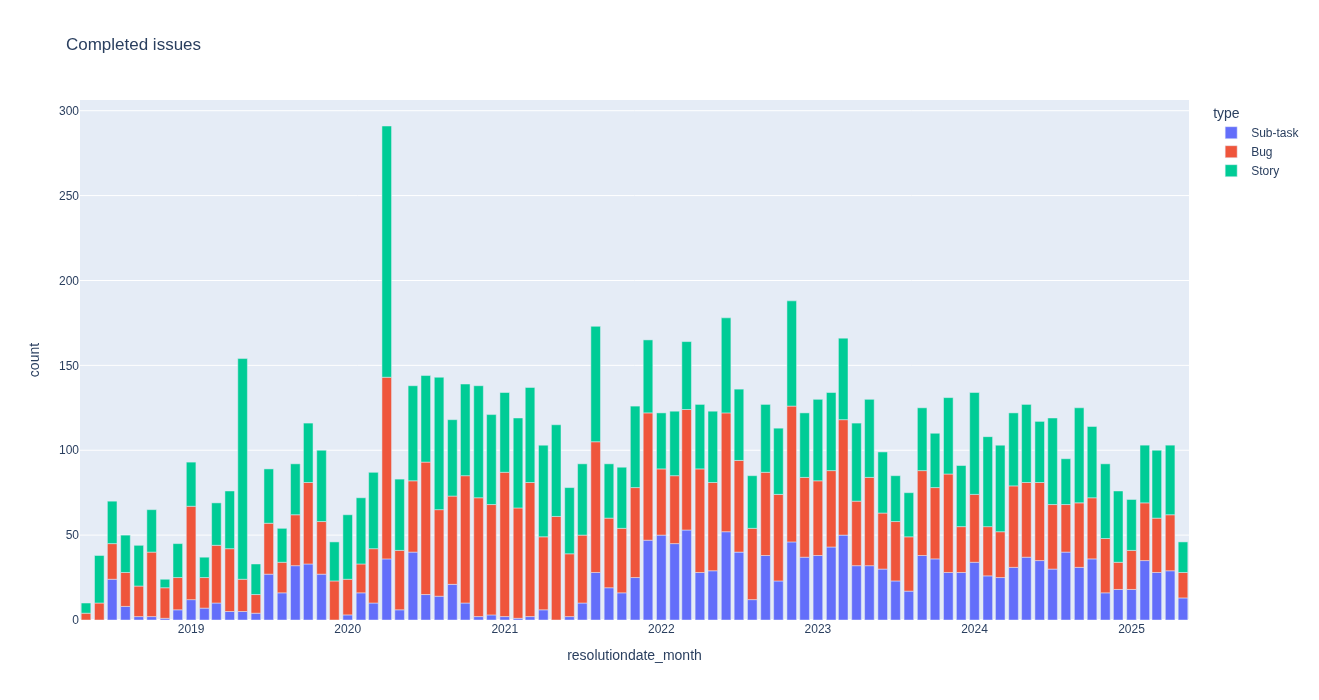

In [27]:
import plotly.express as px
import warnings

warnings.filterwarnings("ignore")

px.bar(
    issues_completed.groupBy('resolutiondate_month','type').count().toPandas(),
    x='resolutiondate_month',
    y='count',
    color='type',
    title='Completed issues',
    height=700)

In [46]:
from pyspark.sql.types import IntegerType, DoubleType

roman_months = {'I':1,'II':2,'III':3,'IV':4,'V':5,'VI':6,'VII':7,'VIII':8,'IX':9,'X':10,'XI':11,'XII':12}

days = [d for d in range(1,31)]

@udf
def month_number(month):
    if month in roman_months.keys():
        return roman_months[month]

day_expr = 'stack(31'

for day in days:
    day_expr = day_expr + f',{day},`{day}`'

day_expr = day_expr + ') as (day,hours)'

ts = spark.read.options(header=True)\
.csv('../data/timesheets/*.csv')\
.withColumn('month', month_number(f.col('Month')))\
.selectExpr(
    'Year as year',
    'month',
    day_expr,
    'Who as user',
    'Project as project',
    '`Jira-id` as jira_id',
    '`Task (description internal)` as task_desc',
    'Category as category')\
.withColumn('year',f.col('year').cast(IntegerType()))\
.withColumn('month',f.col('month').cast(IntegerType()))\
.withColumn('hours',f.col('hours').cast(DoubleType()))\
.withColumn('day',f.to_timestamp(f.concat_ws('-', 'year', 'month', 'day'), 'yyyy-M-d'))\
.withColumn('month',f.date_trunc('month',f.col('day')))\
.drop('year')\
.where(f.col('hours').isNotNull())\
.where(f.col('hours') >0)\
.orderBy(f.col('year').desc(),f.col('month').desc(),f.col('day').desc())

ts.printSchema()

root
 |-- month: timestamp (nullable = true)
 |-- day: timestamp (nullable = true)
 |-- hours: double (nullable = true)
 |-- user: string (nullable = true)
 |-- project: string (nullable = true)
 |-- jira_id: string (nullable = true)
 |-- task_desc: string (nullable = true)
 |-- category: string (nullable = true)



In [50]:
issues_open\
.join(ts,ts.jira_id == issues_normalized.key)\
.groupBy('key','summary','type','priority','size','size_points','user')\
.agg(f.sum('hours').alias('total_hours'))\
.where(f.col('total_hours') > 16)\
.orderBy(f.col('total_hours').desc())\
.toPandas()

,key,summary,type,priority,size,size_points,user,total_hours
0,CRYP-9217,[WebTP] problemy z performance w webTP,Story,Medium,None,None,PAn,163.50
1,CRYP-10286,Weryfikacja transakcji giełdowych z giełdy MEXC,Story,Medium,None,None,TGa,100.50
2,CRYP-10285,[Wallet monitor] Połączenie z Vaultem,Story,Medium,M,3,MRy,89.00
3,CRYP-10472,[LPHS] Złe zachowanie funkcjonalności `trailin...,Bug,High,None,None,PGr,86.75
4,CRYP-9477,[CCXT] Dodanie znacznika początku i konca nagr...,Story,Medium,None,None,MRy,85.50
5,CRYP-10461,[WebTP] W presetach strategii nie są zapisywan...,Bug,Medium,None,None,PAn,78.00
6,CRYP-9394,[FlashBots] Bezpieczne tworzenie puli Uniswap,Story,Medium,None,None,DLa,74.50
7,CRYP-10257,[Backtest] Wykonywanie symulacji dla listy ins...,Story,Medium,None,None,TGa,65.00
8,CRYP-10311,[Global position manager] Pierwsza wersja,Story,Medium,None,None,PGr,53.00
9,CRYP-8364,[WebTP] UI properties - refactor,Story,Medium,None,None,PAn,44.00


In [8]:
def duration_days(start,end):
    return f.round((f.unix_timestamp(end) - f.unix_timestamp(start))/86400)

mrs = spark.read.json('../data/gitlab-merge-requests.json')\
.where(f.col('state')=='merged')\
.withColumn('created_at',f.col('created_at').cast(TimestampType()))\
.withColumn('updated_at',f.col('updated_at').cast(TimestampType()))\
.withColumn('closed_at',f.col('closed_at').cast(TimestampType()))\
.withColumn('merged_at',f.col('merged_at').cast(TimestampType()))\
.withColumn('month',f.date_trunc('month',f.col('merged_at')))\
.withColumn('duration_days',duration_days('created_at','merged_at'))\
.withColumn('jira_id',f.concat(f.lit('CRYP-'),f.regexp_extract('source_branch', r'(\d+)', 1)))

#mrs.show()

In [9]:
mrs_count = mrs\
.groupBy('month')\
.agg(f.count('*').alias('count'))\
.orderBy(f.col('month').desc())

project_mrs = projects.join(mrs,projects.id == mrs.project_id)

mrs_count_by_type = project_mrs\
.groupBy('month','project_type')\
.agg(f.count('*').alias('count'))\
.orderBy(f.col('month').desc())

In [10]:
px.bar(mrs_count_by_type.toPandas(),x='month',y='count',color='project_type',title='MR count by project type',height=500)

In [11]:
mrs_duration = project_mrs\
.groupBy('month','project_type')\
.agg(
    f.avg('duration_days').alias('duration_days_avg'),
    f.min('duration_days').alias('duration_days_min'),
    f.max('duration_days').alias('duration_days_max'),
    f.expr('percentile(duration_days, array(0.25,0.5,0.75,0.9,0.99))').alias('duration_days_pct'))\
.withColumn('duration_days_pct25',f.col('duration_days_pct')[0])\
.withColumn('duration_days_pct50',f.col('duration_days_pct')[1])\
.withColumn('duration_days_pct75',f.col('duration_days_pct')[2])\
.withColumn('duration_days_pct90',f.col('duration_days_pct')[3])\
.withColumn('duration_days_pct99',f.col('duration_days_pct')[4])

In [12]:
px.bar(mrs_duration.toPandas(),x='month',y='duration_days_pct50',color='project_type',title='MR duration pct50',height=500,log_y=True,barmode='group')

In [13]:
px.bar(mrs_duration.toPandas(),x='month',y='duration_days_pct75',color='project_type',title='MR duration pct75',height=500,log_y=True,barmode='group')

In [14]:
mrs_comments = project_mrs\
.groupBy('month','project_type')\
.agg(
    f.count('*').alias('count'),
    f.sum('user_notes_count').alias('comments'))\
.withColumn('comments_avg',f.col('comments')/f.col('count'))

In [15]:
px.bar(mrs_comments.toPandas(),x='month',y='comments',color='project_type',title='MR comments',height=500)

In [16]:
commits = spark.read.json('../data/commits/*.json')\
.withColumn('committer',f.split('committer','@')[0])\
.withColumn('createdAt',f.col('createdAt').cast(TimestampType()))\
.withColumn('month',f.date_trunc('month','createdAt'))

project_commits = commits.join(projects,commits.projectId == projects.id)

commits_by_project_type = project_commits\
.groupBy('month','project_type')\
.agg(
    f.count(commits.id).alias('count'),
    f.sum('additions').alias('additions'),
    f.sum('deletions').alias('deletions'))

In [17]:
px.bar(commits_by_project_type.toPandas(),x='month',y='additions',color='project_type',height=500,title='Code additions',log_y=True)

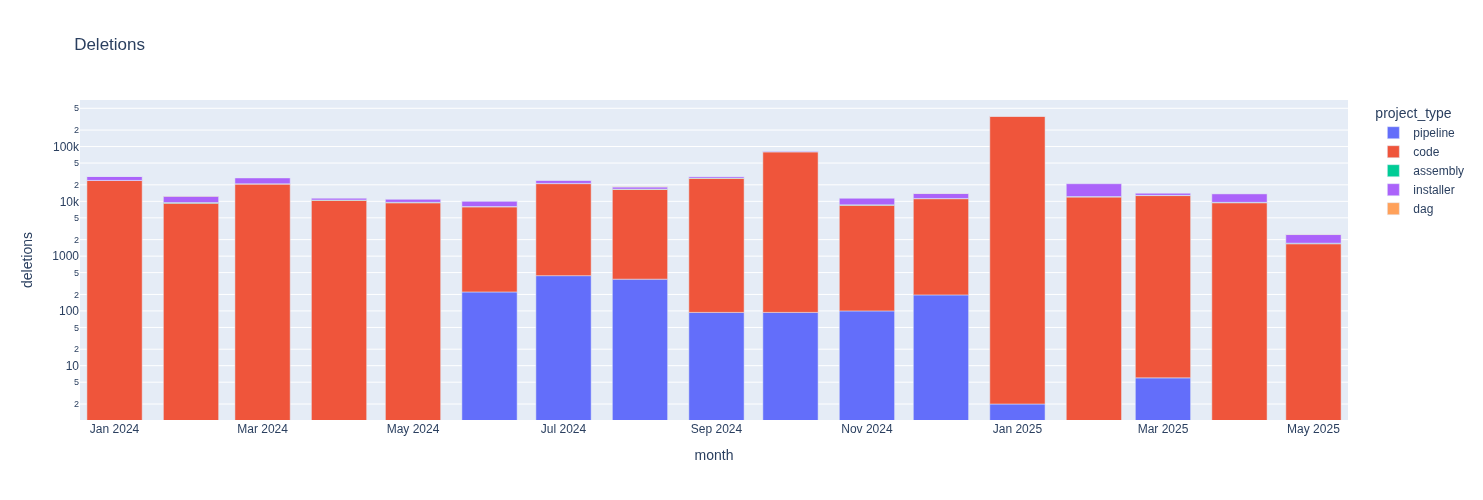

In [18]:
px.bar(commits_by_project_type.toPandas(),x='month',y='deletions',color='project_type',height=500,title='Deletions',log_y=True)